USER DEFINED MODEL THIS WILL BE, AS ALREADY TARGET column and one hot encoding SPECIFIED with respective THRESSHOLD WAS PRESENT AND AGGREGATED AND MODEL PARAMETERS  are unknown!!!


In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import f1_score
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    roc_curve,
    roc_auc_score,
    precision_recall_curve,
    average_precision_score
)



In [ ]:
df = pd.read_excel("/content/default of credit card clients.xls", header=1)

In [ ]:
df.head()

,ID,LIMIT_BAL,SEX,EDUCATION,MARRIAGE,AGE,PAY_0,PAY_2,PAY_3,PAY_4,...,BILL_AMT4,BILL_AMT5,BILL_AMT6,PAY_AMT1,PAY_AMT2,PAY_AMT3,PAY_AMT4,PAY_AMT5,PAY_AMT6,default payment next month
0,1,20000,2,2,1,24,2,2,-1,-1,...,0,0,0,0,689,0,0,0,0,1
1,2,120000,2,2,2,26,-1,2,0,0,...,3272,3455,3261,0,1000,1000,1000,0,2000,1
2,3,90000,2,2,2,34,0,0,0,0,...,14331,14948,15549,1518,1500,1000,1000,1000,5000,0
3,4,50000,2,2,1,37,0,0,0,0,...,28314,28959,29547,2000,2019,1200,1100,1069,1000,0
4,5,50000,1,2,1,57,-1,0,-1,0,...,20940,19146,19131,2000,36681,10000,9000,689,679,0


In [ ]:
df.tail()

,ID,LIMIT_BAL,SEX,EDUCATION,MARRIAGE,AGE,PAY_0,PAY_2,PAY_3,PAY_4,...,BILL_AMT4,BILL_AMT5,BILL_AMT6,PAY_AMT1,PAY_AMT2,PAY_AMT3,PAY_AMT4,PAY_AMT5,PAY_AMT6,default payment next month
29995,29996,220000,1,3,1,39,0,0,0,0,...,88004,31237,15980,8500,20000,5003,3047,5000,1000,0
29996,29997,150000,1,3,2,43,-1,-1,-1,-1,...,8979,5190,0,1837,3526,8998,129,0,0,0
29997,29998,30000,1,2,2,37,4,3,2,-1,...,20878,20582,19357,0,0,22000,4200,2000,3100,1
29998,29999,80000,1,3,1,41,1,-1,0,0,...,52774,11855,48944,85900,3409,1178,1926,52964,1804,1
29999,30000,50000,1,2,1,46,0,0,0,0,...,36535,32428,15313,2078,1800,1430,1000,1000,1000,1


In [ ]:
df.describe()

,ID,LIMIT_BAL,SEX,EDUCATION,MARRIAGE,AGE,PAY_0,PAY_2,PAY_3,PAY_4,...,BILL_AMT4,BILL_AMT5,BILL_AMT6,PAY_AMT1,PAY_AMT2,PAY_AMT3,PAY_AMT4,PAY_AMT5,PAY_AMT6,default payment next month
count,30000.000000,30000.000000,30000.000000,30000.000000,30000.000000,30000.000000,30000.000000,30000.000000,30000.000000,30000.000000,...,30000.000000,30000.000000,30000.000000,30000.000000,3.000000e+04,30000.00000,30000.000000,30000.000000,30000.000000,30000.000000
mean,15000.500000,167484.322667,1.603733,1.853133,1.551867,35.485500,-0.016700,-0.133767,-0.166200,-0.220667,...,43262.948967,40311.400967,38871.760400,5663.580500,5.921163e+03,5225.68150,4826.076867,4799.387633,5215.502567,0.221200
std,8660.398374,129747.661567,0.489129,0.790349,0.521970,9.217904,1.123802,1.197186,1.196868,1.169139,...,64332.856134,60797.155770,59554.107537,16563.280354,2.304087e+04,17606.96147,15666.159744,15278.305679,17777.465775,0.415062
min,1.000000,10000.000000,1.000000,0.000000,0.000000,21.000000,-2.000000,-2.000000,-2.000000,-2.000000,...,-170000.000000,-81334.000000,-339603.000000,0.000000,0.000000e+00,0.00000,0.000000,0.000000,0.000000,0.000000
25%,7500.750000,50000.000000,1.000000,1.000000,1.000000,28.000000,-1.000000,-1.000000,-1.000000,-1.000000,...,2326.750000,1763.000000,1256.000000,1000.000000,8.330000e+02,390.00000,296.000000,252.500000,117.750000,0.000000
50%,15000.500000,140000.000000,2.000000,2.000000,2.000000,34.000000,0.000000,0.000000,0.000000,0.000000,...,19052.000000,18104.500000,17071.000000,2100.000000,2.009000e+03,1800.00000,1500.000000,1500.000000,1500.000000,0.000000
75%,22500.250000,240000.000000,2.000000,2.000000,2.000000,41.000000,0.000000,0.000000,0.000000,0.000000,...,54506.000000,50190.500000,49198.250000,5006.000000,5.000000e+03,4505.00000,4013.250000,4031.500000,4000.000000,0.000000
max,30000.000000,1000000.000000,2.000000,6.000000,3.000000,79.000000,8.000000,8.000000,8.000000,8.000000,...,891586.000000,927171.000000,961664.000000,873552.000000,1.684259e+06,896040.00000,621000.000000,426529.000000,528666.000000,1.000000


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 30000 entries, 0 to 29999
Data columns (total 25 columns):
 #   Column                      Non-Null Count  Dtype
---  ------                      --------------  -----
 0   ID                          30000 non-null  int64
 1   LIMIT_BAL                   30000 non-null  int64
 2   SEX                         30000 non-null  int64
 3   EDUCATION                   30000 non-null  int64
 4   MARRIAGE                    30000 non-null  int64
 5   AGE                         30000 non-null  int64
 6   PAY_0                       30000 non-null  int64
 7   PAY_2                       30000 non-null  int64
 8   PAY_3                       30000 non-null  int64
 9   PAY_4                       30000 non-null  int64
 10  PAY_5                       30000 non-null  int64
 11  PAY_6                       30000 non-null  int64
 12  BILL_AMT1                   30000 non-null  int64
 13  BILL_AMT2                   30000 non-null  int64
 14  BILL_A

In [ ]:
df.shape

(30000, 25)

In [ ]:
df.columns

Index(['ID', 'LIMIT_BAL', 'SEX', 'EDUCATION', 'MARRIAGE', 'AGE', 'PAY_0',
       'PAY_2', 'PAY_3', 'PAY_4', 'PAY_5', 'PAY_6', 'BILL_AMT1', 'BILL_AMT2',
       'BILL_AMT3', 'BILL_AMT4', 'BILL_AMT5', 'BILL_AMT6', 'PAY_AMT1',
       'PAY_AMT2', 'PAY_AMT3', 'PAY_AMT4', 'PAY_AMT5', 'PAY_AMT6',
       'default payment next month'],
      dtype='object')

In [ ]:
df.index

RangeIndex(start=0, stop=30000, step=1)

In [ ]:
print(f'Number of duplicate rows: {df.duplicated().sum()}')

Number of duplicate rows: 0


### Data Cleaning and Preprocessing - data already classified as 0 and 1

In [ ]:
df.head()

,ID,LIMIT_BAL,SEX,EDUCATION,MARRIAGE,AGE,PAY_0,PAY_2,PAY_3,PAY_4,...,BILL_AMT4,BILL_AMT5,BILL_AMT6,PAY_AMT1,PAY_AMT2,PAY_AMT3,PAY_AMT4,PAY_AMT5,PAY_AMT6,default payment next month
0,1,20000,2,2,1,24,2,2,-1,-1,...,0,0,0,0,689,0,0,0,0,1
1,2,120000,2,2,2,26,-1,2,0,0,...,3272,3455,3261,0,1000,1000,1000,0,2000,1
2,3,90000,2,2,2,34,0,0,0,0,...,14331,14948,15549,1518,1500,1000,1000,1000,5000,0
3,4,50000,2,2,1,37,0,0,0,0,...,28314,28959,29547,2000,2019,1200,1100,1069,1000,0
4,5,50000,1,2,1,57,-1,0,-1,0,...,20940,19146,19131,2000,36681,10000,9000,689,679,0


### Logistic Regression Model

First the excel columns were object, as in ML models all data must be in numeric only.

In [ ]:
# Convert all relevant columns to numeric types
for col in df.columns:
    df[col] = pd.to_numeric(df[col], errors='coerce')

# Display info again to confirm data types and check for any remaining non-numeric issues
print("DataFrame after cleaning and type conversion:")
display(df.info())
display(df.head())


DataFrame after cleaning and type conversion:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 30000 entries, 0 to 29999
Data columns (total 25 columns):
 #   Column                      Non-Null Count  Dtype
---  ------                      --------------  -----
 0   ID                          30000 non-null  int64
 1   LIMIT_BAL                   30000 non-null  int64
 2   SEX                         30000 non-null  int64
 3   EDUCATION                   30000 non-null  int64
 4   MARRIAGE                    30000 non-null  int64
 5   AGE                         30000 non-null  int64
 6   PAY_0                       30000 non-null  int64
 7   PAY_2                       30000 non-null  int64
 8   PAY_3                       30000 non-null  int64
 9   PAY_4                       30000 non-null  int64
 10  PAY_5                       30000 non-null  int64
 11  PAY_6                       30000 non-null  int64
 12  BILL_AMT1                   30000 non-null  int64
 13  BILL_AMT2      

None

,ID,LIMIT_BAL,SEX,EDUCATION,MARRIAGE,AGE,PAY_0,PAY_2,PAY_3,PAY_4,...,BILL_AMT4,BILL_AMT5,BILL_AMT6,PAY_AMT1,PAY_AMT2,PAY_AMT3,PAY_AMT4,PAY_AMT5,PAY_AMT6,default payment next month
0,1,20000,2,2,1,24,2,2,-1,-1,...,0,0,0,0,689,0,0,0,0,1
1,2,120000,2,2,2,26,-1,2,0,0,...,3272,3455,3261,0,1000,1000,1000,0,2000,1
2,3,90000,2,2,2,34,0,0,0,0,...,14331,14948,15549,1518,1500,1000,1000,1000,5000,0
3,4,50000,2,2,1,37,0,0,0,0,...,28314,28959,29547,2000,2019,1200,1100,1069,1000,0
4,5,50000,1,2,1,57,-1,0,-1,0,...,20940,19146,19131,2000,36681,10000,9000,689,679,0


In [ ]:
df = df.rename(columns={'default payment next month': 'default_payment_next_month'})

In [ ]:
# Drop the 'ID' column as it's not a feature for the model
#ID removed because of No predictive power, prevents overfitting, irrelevant noise
X = df.drop(columns=['default_payment_next_month'])
y = df['default_payment_next_month']
X.columns = X.columns.astype(str)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)
print("Data split into training and testing sets successfully.")
print(f"X_train shape: {X_train.shape}")
print(f"X_test shape: {X_test.shape}")
print(f"y_train shape: {y_train.shape}")
print(f"y_test shape: {y_test.shape}")


Data split into training and testing sets successfully.
X_train shape: (21000, 24)
X_test shape: (9000, 24)
y_train shape: (21000,)
y_test shape: (9000,)


In [ ]:
model = LogisticRegression(max_iter=1000, random_state=42, solver='liblinear', class_weight='balanced')
model.fit(X_train, y_train)

LogisticRegression(class_weight='balanced', max_iter=1000, random_state=42,
                   solver='liblinear')

In [ ]:
y_pred = model.predict(X_test)
print("Model Evaluation:")
print("Accuracy:", accuracy_score(y_test, y_pred))
print("\nConfusion Matrix:\n", confusion_matrix(y_test, y_pred))
print("\nClassification Report:\n", classification_report(y_test, y_pred))


train_pred = model.predict(X_train)
test_pred = model.predict(X_test)

train_acc = accuracy_score(y_train, train_pred)
test_acc = accuracy_score(y_test, test_pred)

train_f1 = f1_score(y_train, train_pred)
test_f1 = f1_score(y_test, test_pred)

print("Training Accuracy:", train_acc)
print("Testing Accuracy :", test_acc)

print("Training F1:", train_f1)
print("Testing F1 :", test_f1)

print("Accuracy Gap:", train_acc - test_acc)
print("F1 Gap:", train_f1 - test_f1)


Model Evaluation:
Accuracy: 0.6578888888888889

Confusion Matrix:
 [[4697 2343]
 [ 736 1224]]

Classification Report:
               precision    recall  f1-score   support

           0       0.86      0.67      0.75      7040
           1       0.34      0.62      0.44      1960

    accuracy                           0.66      9000
   macro avg       0.60      0.65      0.60      9000
weighted avg       0.75      0.66      0.69      9000

Training Accuracy: 0.6635238095238095
Testing Accuracy : 0.6578888888888889
Training F1: 0.45746314496314494
Testing F1 : 0.44291659127917493
Accuracy Gap: 0.005634920634920659
F1 Gap: 0.01454655368397001


Conclusion : high-bias / underfitting

CLASS IMBALANCE
usually 40, 40 or 50 , 50 or 60, 40 or more
This is around 90 , 10

In [ ]:
print("Distribution of 'default_payment_next_month' (y):")
display(y.value_counts())

Distribution of 'default_payment_next_month' (y):


,count
default_payment_next_month,
0,23364
1,6636


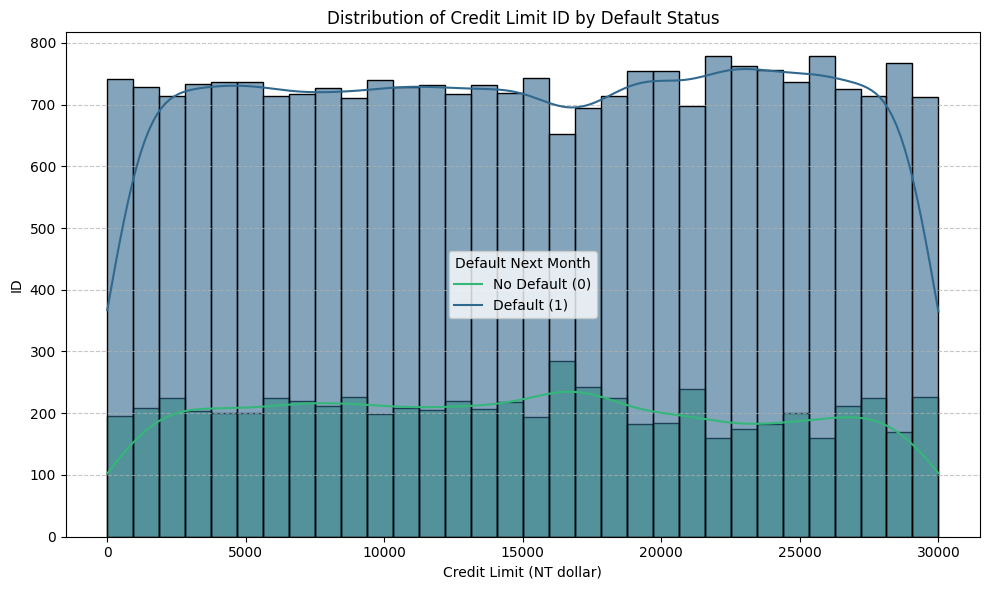

In [ ]:
plt.figure(figsize=(10, 6))
sns.histplot(data=df, x='ID', hue='default_payment_next_month', kde=True, palette='viridis', alpha=0.6)
plt.title('Distribution of Credit Limit ID by Default Status')
plt.xlabel('Credit Limit (NT dollar)')
plt.ylabel('ID')
plt.legend(title='Default Next Month', labels=['No Default (0)', 'Default (1)'])
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()
#This visualization supports the idea that 'LIMIT_BAL' is an important feature,
# and its value can influence the likelihood of default, but it also highlights the complexity of the prediction problem due to the overlapping distributions.

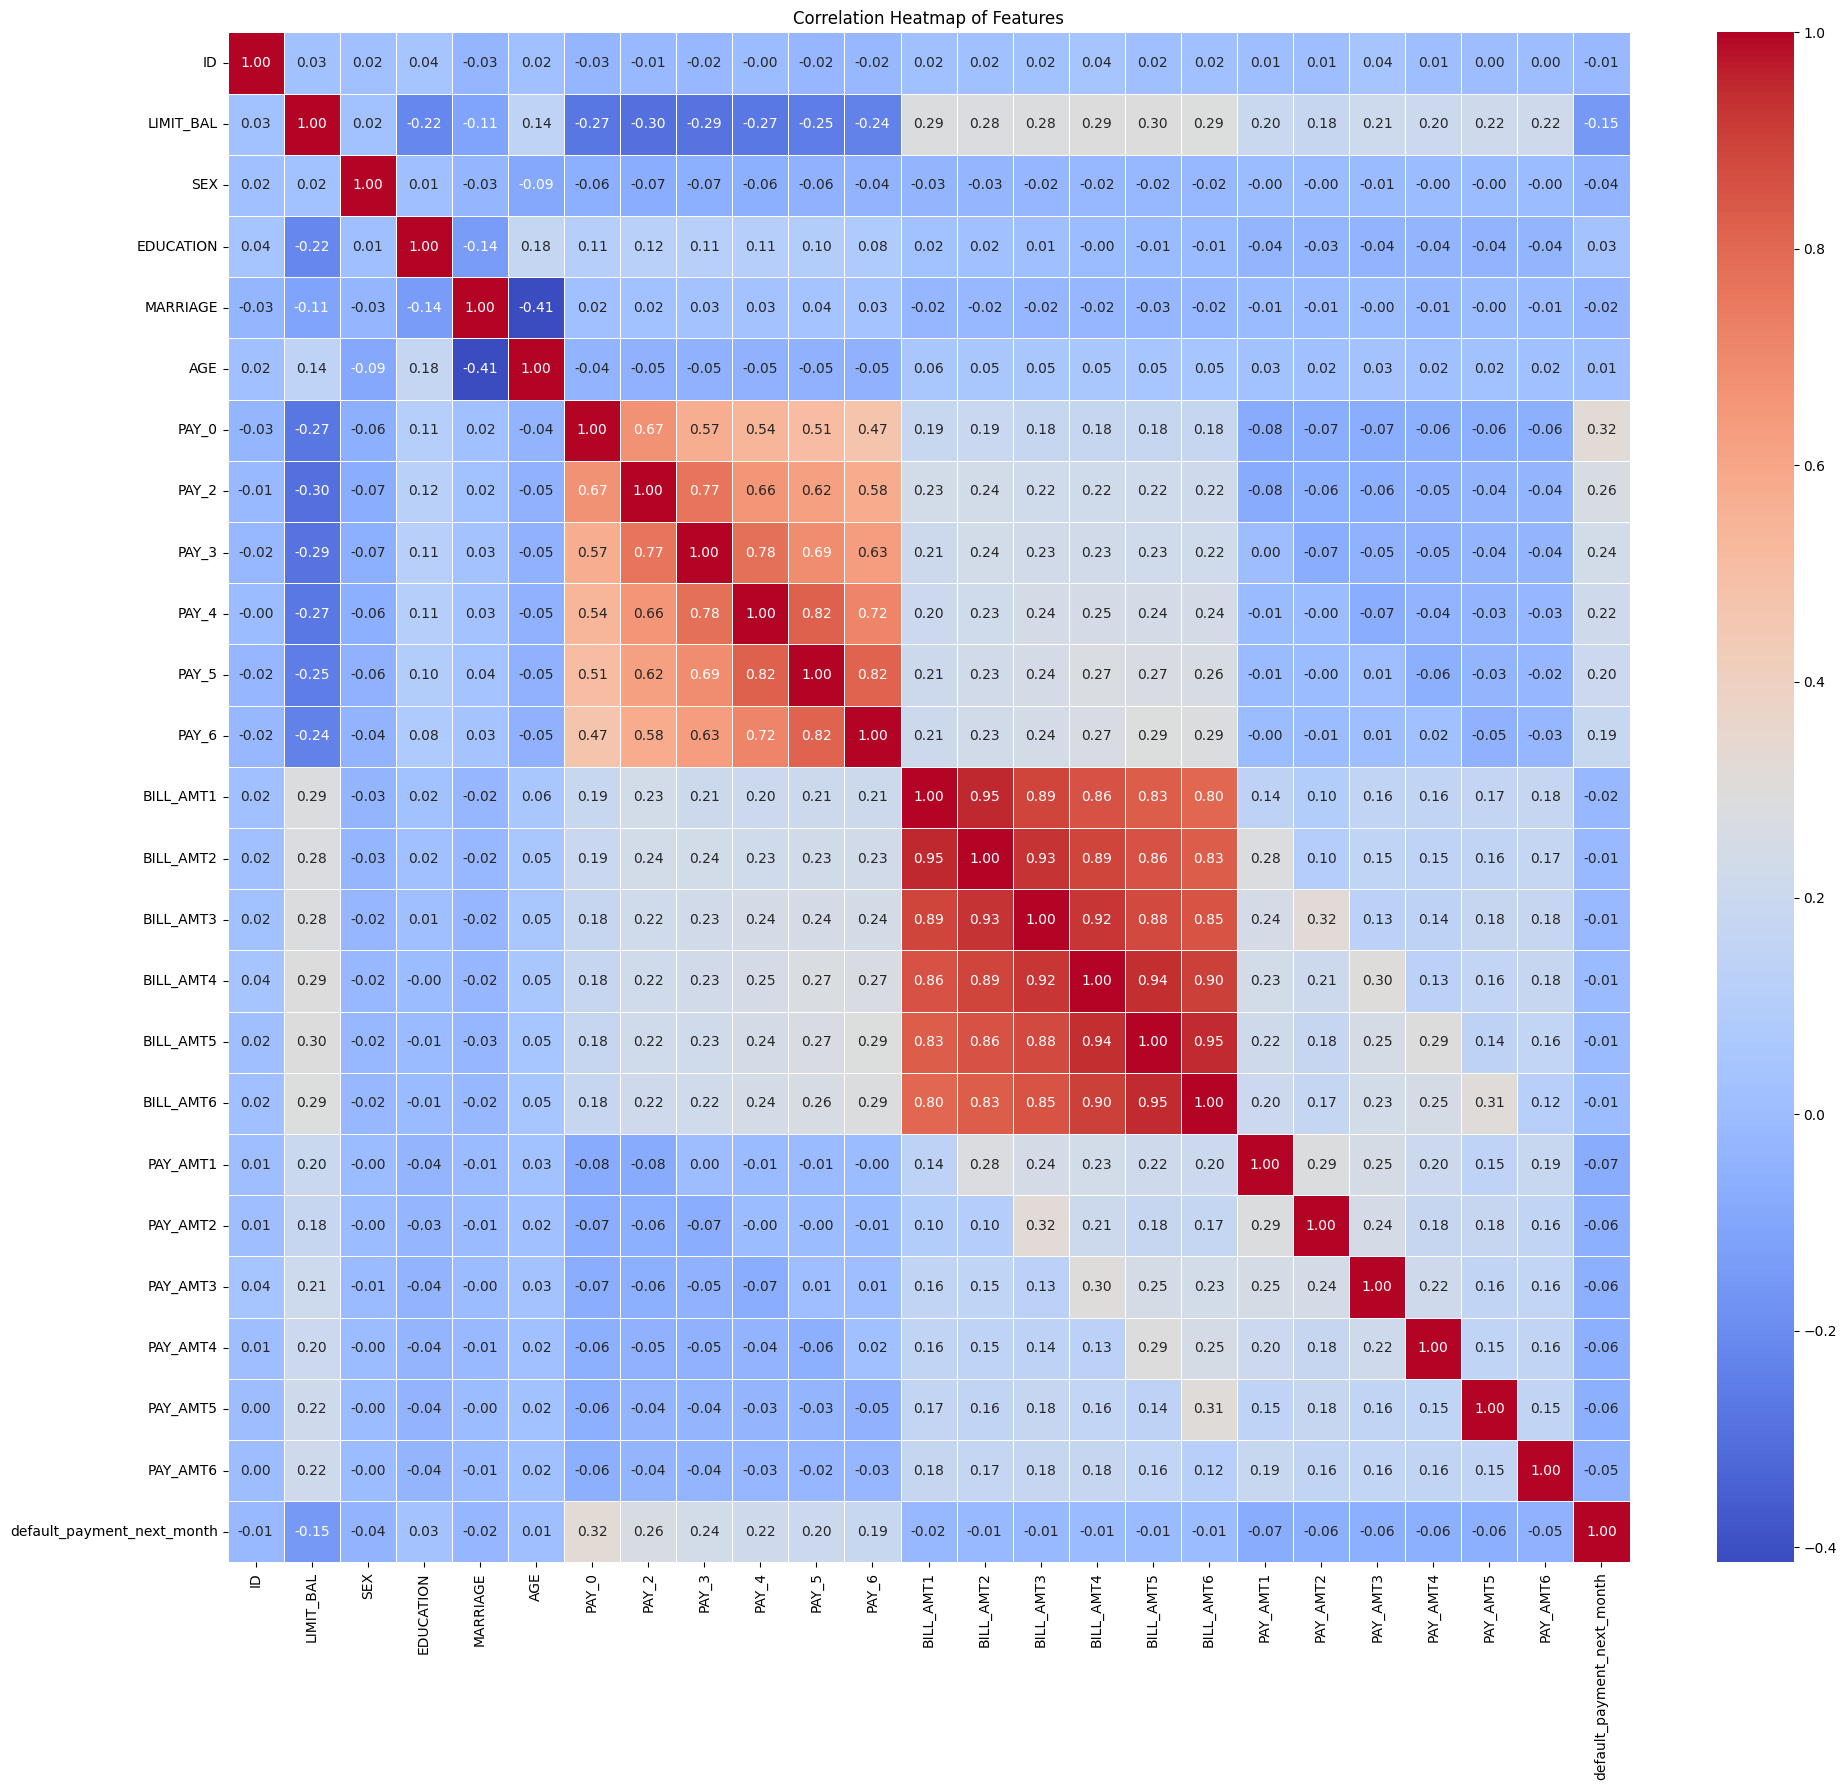

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# Calculate the correlation matrix
corr_matrix = df.corr()

plt.figure(figsize=(20, 18))
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', fmt='.2f', linewidths=.5)
plt.title('Correlation Heatmap of Features')
plt.xticks(rotation=90)
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

Overall, the heatmap suggests that repayment history (PAY_0–PAY_6) is the most important group of variables for predicting credit-card default, while the other demographic variables have relatively weak linear relationships with the target.

In [ ]:
feature_names = X_train.columns
coefficients = model.coef_[0] if model.coef_.ndim > 1 else model.coef_
feature_importance_df = pd.DataFrame({
    'Feature': feature_names,
    'Coefficient': coefficients
})
feature_importance_df['Abs_Coefficient'] = feature_importance_df['Coefficient'].abs()
feature_importance_df = feature_importance_df.sort_values(by='Abs_Coefficient', ascending=False)

display(feature_importance_df)

,Feature,Coefficient,Abs_Coefficient
5,PAY_0,2.780063e-01,2.780063e-01
6,PAY_2,1.570391e-01,1.570391e-01
7,PAY_3,1.117486e-01,1.117486e-01
8,PAY_4,8.251524e-02,8.251524e-02
9,PAY_5,6.367958e-02,6.367958e-02
10,PAY_6,5.752341e-02,5.752341e-02
2,EDUCATION,-1.931625e-02,1.931625e-02
1,SEX,-1.789632e-02,1.789632e-02
3,MARRIAGE,-1.628404e-02,1.628404e-02
4,AGE,9.654671e-03,9.654671e-03


From this table, you can see which features have the largest impact (positive or negative) on the likelihood of 'default_payment_next_month'. For example, features like `PAY_0`, `PAY_2`, etc., typically have high positive coefficients, indicating that delays in payment significantly increase the probability of default.

### Detect Multicollinearity using Variance Inflation Factor (VIF)

Multicollinearity occurs when independent variables in a regression model are correlated. It can make it difficult to interpret the individual coefficients of the model and can inflate their standard errors, leading to less reliable statistical inferences. We will use the Variance Inflation Factor (VIF) to quantify the severity of multicollinearity in our features.

A VIF value of:
- **1**: No correlation between the 'i'th predictor and the remaining predictor variables.
- **1 to 5**: Moderate correlation.
- **> 5 or 10**: High correlation (problematic).



In [ ]:
from statsmodels.stats.outliers_influence import variance_inflation_factor
vif_data = pd.DataFrame()
vif_data["feature"] = X.columns
vif_data["VIF"] = [variance_inflation_factor(X.values, i) for i in range(len(X.columns))]
vif_data = vif_data.sort_values(by="VIF", ascending=False).reset_index(drop=True)
display(vif_data)


,feature,VIF
0,BILL_AMT2,38.214225
1,BILL_AMT5,35.986369
2,BILL_AMT3,31.783029
3,BILL_AMT4,29.548135
4,BILL_AMT6,21.426076
5,BILL_AMT1,20.823400
6,AGE,10.857679
7,SEX,9.092210
8,EDUCATION,6.731119
9,MARRIAGE,6.265388


Repayment history (PAY_0–PAY_6) is the strongest and most reliable feature group for predicting default. The BILL_AMT variables have very high multicollinearity (VIF > 20), meaning they provide highly overlapping information, which can make Logistic Regression coefficients unstable. AGE, SEX, EDUCATION, and MARRIAGE have relatively weak correlations with the target, while some also show moderate/high VIF. Therefore, for improving your Logistic Regression model, PAY variables should definitely be retained, while the highly correlated BILL_AMT variables are candidates for feature reduction or dimensionality reduction.

Conclusion Feature selection specifically doesn't work on  under fitting
Logistic Regression, being a linear model, generally performs well when the relationship between the features and the target variable is predominantly linear, if multi possibilities occurs bias over the model

### Building a Random Forest Classifier

Given the limitations observed with Logistic Regression, particularly with class imbalance and multicollinearity, a tree-based ensemble method like Random Forest is a strong alternative. Random Forests are known for their ability to handle complex, non-linear relationships, are less sensitive to multicollinearity, and can implicitly manage class imbalance through strategies like `class_weight`.

We will use the full set of features (`X`) for the Random Forest model, as these models are generally more robust to multicollinearity than linear models.

In [ ]:
dt = pd.read_excel("/content/default of credit card clients.xls",header=1)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 30000 entries, 0 to 29999
Data columns (total 25 columns):
 #   Column                      Non-Null Count  Dtype
---  ------                      --------------  -----
 0   ID                          30000 non-null  int64
 1   LIMIT_BAL                   30000 non-null  int64
 2   SEX                         30000 non-null  int64
 3   EDUCATION                   30000 non-null  int64
 4   MARRIAGE                    30000 non-null  int64
 5   AGE                         30000 non-null  int64
 6   PAY_0                       30000 non-null  int64
 7   PAY_2                       30000 non-null  int64
 8   PAY_3                       30000 non-null  int64
 9   PAY_4                       30000 non-null  int64
 10  PAY_5                       30000 non-null  int64
 11  PAY_6                       30000 non-null  int64
 12  BILL_AMT1                   30000 non-null  int64
 13  BILL_AMT2                   30000 non-null  int64
 14  BILL_A

None

,ID,LIMIT_BAL,SEX,EDUCATION,MARRIAGE,AGE,PAY_0,PAY_2,PAY_3,PAY_4,...,BILL_AMT4,BILL_AMT5,BILL_AMT6,PAY_AMT1,PAY_AMT2,PAY_AMT3,PAY_AMT4,PAY_AMT5,PAY_AMT6,default_payment_next_month
0,1,20000,2,2,1,24,2,2,-1,-1,...,0,0,0,0,689,0,0,0,0,1
1,2,120000,2,2,2,26,-1,2,0,0,...,3272,3455,3261,0,1000,1000,1000,0,2000,1
2,3,90000,2,2,2,34,0,0,0,0,...,14331,14948,15549,1518,1500,1000,1000,1000,5000,0
3,4,50000,2,2,1,37,0,0,0,0,...,28314,28959,29547,2000,2019,1200,1100,1069,1000,0
4,5,50000,1,2,1,57,-1,0,-1,0,...,20940,19146,19131,2000,36681,10000,9000,689,679,0



Random Forest Model Evaluation:
Accuracy: 0.8126666666666666

Confusion Matrix:
 [[4440  233]
 [ 891  436]]

Classification Report:
               precision    recall  f1-score   support

           0       0.83      0.95      0.89      4673
           1       0.65      0.33      0.44      1327

    accuracy                           0.81      6000
   macro avg       0.74      0.64      0.66      6000
weighted avg       0.79      0.81      0.79      6000


================ CONFUSION MATRIX ================
[[4440  233]
 [ 891  436]]


<Figure size 700x500 with 0 Axes>

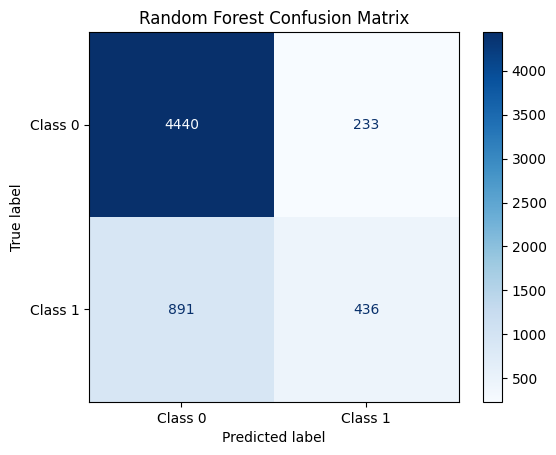

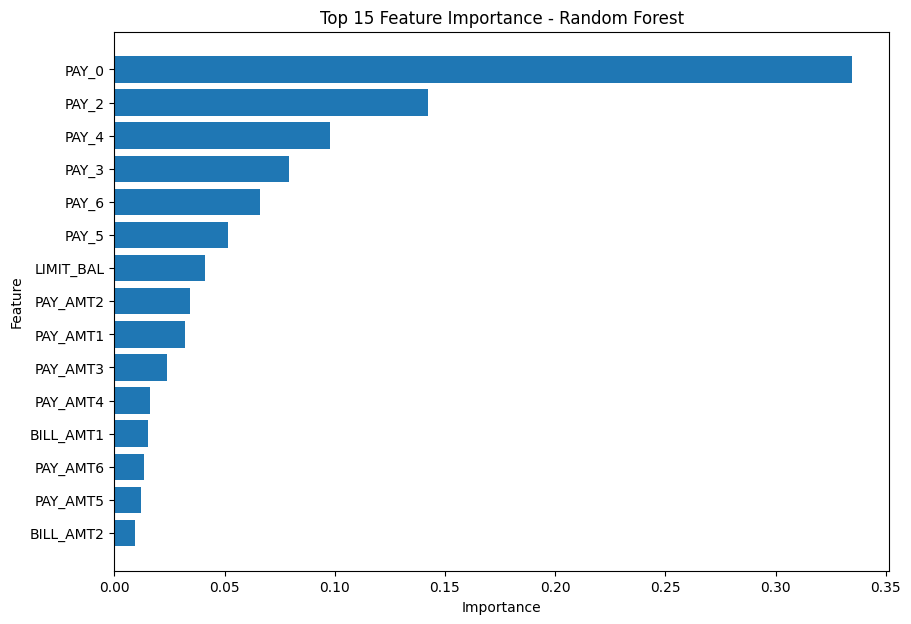

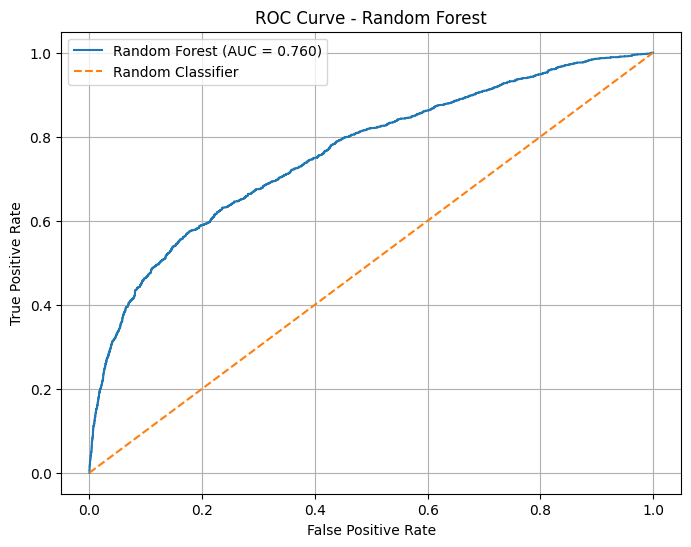


ROC-AUC: 0.7604789559738955


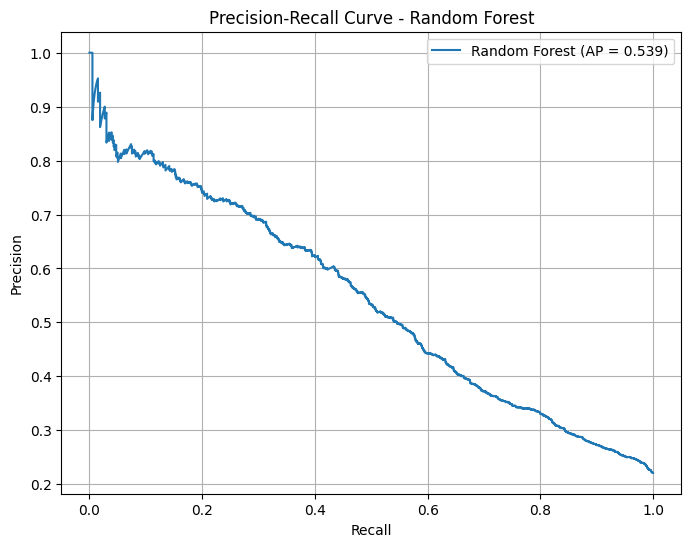


================ ACTUAL VS PREDICTED ================
   Actual  Predicted
0    4673       5331
1    1327        669


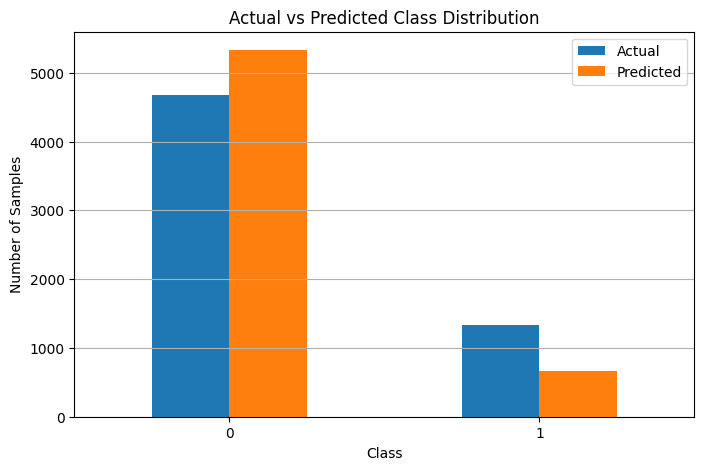

In [ ]:
# Convert all relevant columns to numeric types
for col in dt.columns:
    dt[col] = pd.to_numeric(dt[col], errors='coerce')

# Display info again to confirm data types and check for any remaining non-numeric issues
dt = dt.rename(columns={'default payment next month': 'default_payment_next_month'})
X = dt.drop(columns=[target_col])
y = dt[target_col].astype(int)
display(dt.info())
display(dt.head())
X_train, X_test, y_train, y_test = train_test_split( X, y,test_size=0.20,random_state=42,stratify=y)
rf_model = RandomForestClassifier(n_estimators=100, random_state=42, class_weight='balanced', n_jobs=-1)
rf_model.fit(X_train, y_train)
y_pred_rf = rf_model.predict(X_test)
print("\nRandom Forest Model Evaluation:")
print("Accuracy:", accuracy_score(y_test, y_pred_rf))
print("\nConfusion Matrix:\n", confusion_matrix(y_test, y_pred_rf))
print("\nClassification Report:\n", classification_report(y_test, y_pred_rf))

cm = confusion_matrix(y_test, test_pred)
print("\n================ CONFUSION MATRIX ================")
print(cm)
plt.figure(figsize=(7, 5))
disp = ConfusionMatrixDisplay(confusion_matrix=cm,display_labels=["Class 0", "Class 1"])
disp.plot(cmap="Blues")
plt.title("Random Forest Confusion Matrix")
plt.show()
top_features = feature_importance.head(15)
plt.figure(figsize=(10, 7))
plt.barh(top_features["Feature"][::-1],top_features["Importance"][::-1])
plt.xlabel("Importance")
plt.ylabel("Feature")
plt.title("Top 15 Feature Importance - Random Forest")
plt.show()

# ============================================================
#  ROC CURVE
# ============================================================
roc_auc = roc_auc_score(y_test,test_prob)
fpr, tpr, thresholds = roc_curve(y_test,test_prob)
plt.figure(figsize=(8, 6))
plt.plot(fpr,tpr,label=f"Random Forest (AUC = {roc_auc:.3f})")
plt.plot([0, 1],[0, 1],linestyle="--",label="Random Classifier")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve - Random Forest")
plt.legend()
plt.grid(True)
plt.show()
print("\nROC-AUC:", roc_auc)

# ============================================================
#  PRECISION-RECALL CURVE
# ============================================================
precision, recall, pr_thresholds = precision_recall_curve(y_test,test_prob)
average_precision = average_precision_score(y_test,test_prob)
plt.figure(figsize=(8, 6))
plt.plot(recall,precision,label=f"Random Forest (AP = {average_precision:.3f})")
plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Precision-Recall Curve - Random Forest")
plt.legend()
plt.grid(True)
plt.show()

# ============================================================
# ACTUAL VS PREDICTED CLASS DISTRIBUTION
# ============================================================
actual_counts = pd.Series(y_test).value_counts().sort_index()
predicted_counts = pd.Series(test_pred).value_counts().sort_index()
comparison = pd.DataFrame({"Actual": actual_counts,"Predicted": predicted_counts})
print("\n================ ACTUAL VS PREDICTED ================")
print(comparison)
comparison.plot(kind="bar",figsize=(8, 5))
plt.xlabel("Class")
plt.ylabel("Number of Samples")
plt.title("Actual vs Predicted Class Distribution")
plt.xticks(rotation=0)
plt.legend()
plt.grid(axis="y")
plt.show()

Therefore, among the six data mining techniques discussed in the paper which said logistic won't be accurate to be used and rest tree algo isn't efficient enough, artificial neural network is the only one that can accurately estimate the real probability of default as confirmed in the paper.

In [ ]:
# ============================================================
# CREDIT CARD DEFAULT - ARTIFICIAL NEURAL NETWORK
# ============================================================

file_path = "/content/default of credit card clients.xls"
dx = pd.read_excel(file_path, header=1)
dx = dx.rename(columns={'default payment next month': 'default_payment_next_month'})
for col in dt.columns:
    dx[col] = pd.to_numeric(dx[col], errors='coerce')

X = dx.drop(columns=[target_col])
y = dx[target_col].astype(int)


target_col = "default_payment_next_month"
X = df.drop(columns=[target_col])
y = df[target_col].astype(int)
X_train_full, X_test, y_train_full, y_test = train_test_split(X,y,test_size=0.20,random_state=42,stratify=y)
X_train, X_val, y_train, y_val = train_test_split(X_train_full,y_train_full,test_size=0.20,random_state=42,stratify=y_train_full)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_val_scaled = scaler.transform(X_val)
X_test_scaled = scaler.transform(X_test)

tf.random.set_seed(42)
np.random.seed(42)
model = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(X_train_scaled.shape[1],)),
    tf.keras.layers.Dense(256,activation="relu"),tf.keras.layers.BatchNormalization(),
    tf.keras.layers.Dense(128,activation="relu"),tf.keras.layers.BatchNormalization(),
    tf.keras.layers.Dense(64,activation="relu"),
    tf.keras.layers.Dense(32,activation="relu"),
    tf.keras.layers.Dropout(0.10),
    tf.keras.layers.Dense(1,activation="sigmoid")
])

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.0005),loss="binary_crossentropy",metrics=[tf.keras.metrics.BinaryAccuracy(name="accuracy"),tf.keras.metrics.AUC(name="auc")])
model.summary()
early_stopping = tf.keras.callbacks.EarlyStopping(monitor="val_loss",patience=20,restore_best_weights=True,verbose=1)
reduce_lr = tf.keras.callbacks.ReduceLROnPlateau(monitor="val_loss",factor=0.5,patience=7,min_lr=0.00001,verbose=1)
history = model.fit(X_train_scaled,y_train,validation_data=(X_val_scaled,y_val),epochs=200,batch_size=64,callbacks=[early_stopping,reduce_lr],verbose=1)
train_prob = model.predict(X_train_scaled,verbose=0).ravel()
val_prob = model.predict(X_val_scaled,verbose=0).ravel()
test_prob = model.predict(X_test_scaled,verbose=0).ravel()
threshold = 0.50
train_pred = (train_prob >= threshold).astype(int)
val_pred = (val_prob >= threshold).astype(int)
test_pred = (test_prob >= threshold).astype(int)

def show_metrics(name, y_true, y_pred, probabilities):

    accuracy = accuracy_score(y_true, y_pred)

    precision = precision_score(
        y_true,
        y_pred,
        zero_division=0
    )

    recall = recall_score(
        y_true,
        y_pred,
        zero_division=0
    )

    f1 = f1_score(
        y_true,
        y_pred,
        zero_division=0
    )

    roc_auc = roc_auc_score(
        y_true,
        probabilities
    )

    print("\n====================================")
    print(name)
    print("====================================")

    print("Accuracy  :", round(accuracy, 4))
    print("Precision :", round(precision, 4))
    print("Recall    :", round(recall, 4))
    print("F1 Score  :", round(f1, 4))
    print("ROC-AUC   :", round(roc_auc, 4))

    return accuracy

# ============================================================
# 14. METRICS FUNCTION
# ============================================================

def show_metrics(
    name,
    y_true,
    y_pred,
    probabilities
):

    accuracy = accuracy_score(
        y_true,
        y_pred
    )

    precision = precision_score(
        y_true,
        y_pred,
        zero_division=0
    )

    recall = recall_score(
        y_true,
        y_pred,
        zero_division=0
    )

    f1 = f1_score(
        y_true,
        y_pred,
        zero_division=0
    )

    roc_auc = roc_auc_score(
        y_true,
        probabilities
    )

    avg_precision = average_precision_score(
        y_true,
        probabilities
    )

    print("\n------------------------------------------------------------")
    print(name)
    print("------------------------------------------------------------")

    print("Accuracy          :", round(accuracy, 4))
    print("Precision         :", round(precision, 4))
    print("Recall            :", round(recall, 4))
    print("F1                :", round(f1, 4))
    print("ROC-AUC           :", round(roc_auc, 4))
    print("Average Precision :", round(avg_precision, 4))

    return accuracy, f1


# ============================================================
# CONFUSION MATRIX
# ============================================================

cm = confusion_matrix(
    y_test,
    test_pred
)

print("\n============================================================")
print("CONFUSION MATRIX")
print("============================================================")

print(cm)
train_prob = model.predict(X_train_scaled).ravel()
test_prob = model.predict(X_test_scaled).ravel()

train_pred = (train_prob >= 0.5).astype(int)
test_pred = (test_prob >= 0.5).astype(int)

print("Training Accuracy:", accuracy_score(y_train, train_pred))
print("Testing Accuracy :", accuracy_score(y_test, test_pred))

print("Training F1:", f1_score(y_train, train_pred))
print("Testing F1 :", f1_score(y_test, test_pred))
model.save("/content/credit_card_default_ann.keras")

Model: "sequential_6"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_30 (Dense)                │ (None, 256)            │         6,400 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_13          │ (None, 256)            │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_31 (Dense)                │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_14          │ (None, 128)            │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_32 (Dense)                │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_33 (Dense)                │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_9 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_34 (Dense)                │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 51,201 (200.00 KB)

 Trainable params: 50,433 (197.00 KB)

 Non-trainable params: 768 (3.00 KB)

Epoch 1/200
300/300 ━━━━━━━━━━━━━━━━━━━━ 5s 6ms/step - accuracy: 0.8077 - auc: 0.7360 - loss: 0.4611 - val_accuracy: 0.8135 - val_auc: 0.7572 - val_loss: 0.4572 - learning_rate: 5.0000e-04
Epoch 2/200
300/300 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.8199 - auc: 0.7766 - loss: 0.4312 - val_accuracy: 0.8148 - val_auc: 0.7593 - val_loss: 0.4459 - learning_rate: 5.0000e-04
Epoch 3/200
300/300 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.8249 - auc: 0.7942 - loss: 0.4187 - val_accuracy: 0.8154 - val_auc: 0.7614 - val_loss: 0.4471 - learning_rate: 5.0000e-04
Epoch 4/200
300/300 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.8294 - auc: 0.8070 - loss: 0.4098 - val_accuracy: 0.8129 - val_auc: 0.7611 - val_loss: 0.4480 - learning_rate: 5.0000e-04
Epoch 5/200
300/300 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.8292 - auc: 0.8209 - loss: 0.3995 - val_accuracy: 0.8140 - val_auc: 0.7619 - val_loss: 0.4494 - learning_rate: 5.0000e-04
Epoch 6/200
300/300 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - 

OVERFITTING

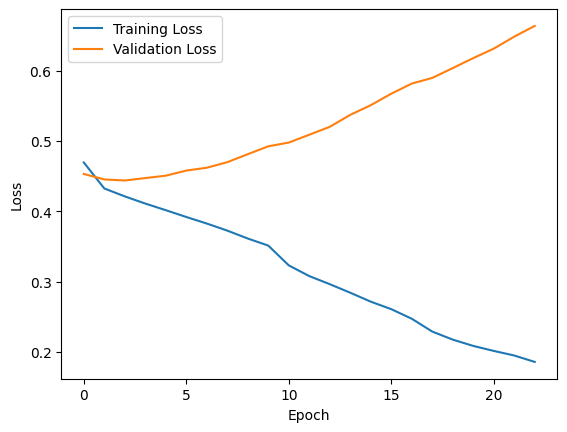

In [ ]:
plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.show()

Reducing no of features/Columns\ is must
Target variable wise onder fitting
features wise over fitting